# Making pie charts in Python: Exercise solution

This is the code used to produce the exercise solution from the **Making pie charts in Python** script. Compare your code and output against the code and output produced here to see how well you did. Note that your code and output do not need to match the solution exactly to be considered correct!

Can you think of any other ways of making the pie chart more accessible?

The pie chart should:

-   Show the size of vulnerable populations in Argentina, Malawi, Nepal, and the United Kingdom in the year 2007
-   Be formatted so that:
    -   The countries are ordered so that the pie chart is ordered clockwise from largest to smallest, starting at 12 o'clock
    -   The largest sector is HEX code #D17E38
    -   The second largest sector is HEX code #444443
    -   The third largest sector is HEX code #3EA27F
    -   The smallest sector is HEX code #752111
    -   Include data labels containing each country's name and its percentage of the total vulnerable population
    -   There is no legend
    -   There are white borders between sectors
    -   The chart is exported with the file name: vuln_pie_solution
    -   The chart is saved to the exercise_outputs folder
    -   The plot can be saved as both .svg chart  

# Setup

In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

os.chdir(r"D:\repos\analysis-for-action")

# Load the dataset
vuln = pd.read_csv("learning_resources/data/vulnerable.csv")

# Preparing the data

In [2]:
vuln_partner_countries = vuln[(vuln['year'] == 2007) & (vuln['country'].isin(["United Kingdom", "Argentina", "Malawi", "Nepal"]))]
# order from largest to smallest
vuln_partner_countries = vuln_partner_countries.sort_values(by='vulnerable_pop', ascending=False)

print(vuln_partner_countries)

             country continent  year  vulnerable_pop  lower_confidence_limit  \
1607  United Kingdom    Europe  2007        12155248                12073808   
59         Argentina  Americas  2007         8060385                 8019277   
1079           Nepal      Asia  2007         5780358                 5713884   
935           Malawi    Africa  2007         2665416                 2649957   

      upper_confidence_limit  
1607                12361887  
59                   8278015  
1079                 5904636  
935                  2710728  


# Creating the pie chart

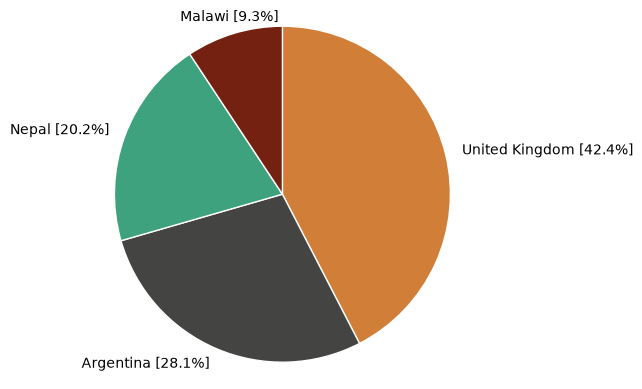

In [7]:
country_colours = {
    "United Kingdom": "#D17E38",
    "Argentina": "#444443",
    "Nepal": "#3EA27F",
    "Malawi": "#752111"}

percentages = (vuln_partner_countries['vulnerable_pop'] / vuln_partner_countries['vulnerable_pop'].sum() * 100)

country_labels = [f"{country} [{percentage:.1f}%]" for country, percentage in zip(vuln_partner_countries['country'], percentages)]

vuln_pie_solution = plt.pie(vuln_partner_countries['vulnerable_pop'], labels=country_labels, startangle=90, counterclock=False,
                                # add white border between sectors
                                wedgeprops={'edgecolor': 'white'},
                                colors=[country_colours[country] for country in vuln_partner_countries['country']])
# Equal aspect ratio ensures that pie is drawn as a circle
plt.axis('equal')  
# Change alignment based on the position of the label (adjusted to align Denmark to right due to increased label length)
for label in vuln_pie_solution[1]:
    x, y = label.get_position()

    label.set_position((x, y))

    if x > 0.4:
        label.set_horizontalalignment('left')
    elif x < -0.4:
        label.set_horizontalalignment('right')
    else:
        label.set_horizontalalignment('center')

# Save the pie chart as an svg file
plt.savefig("learning_resources/outputs_and_reporting/data_visualisation/basic_data_visualisation/python/exercise_outputs/vuln_pie_solution.svg", format="svg")